# 局部热源自由衰减与无反馈光学预测

研究顺序：固定随机传播 → 单次加热后的自由冷却 → 不同条件下的 speckle → Mackey–Glass 预测 → 检验输入历史是否真正被储存。

**重要模型约定：** 加热在 $k=0$ 前发生，初始热状态 $\theta_0=1$。之后输入光只用于探测/编码，不给热源写入信息；没有电子反馈。本 notebook 因此是物理特性和预测 **baseline**，不是输入 fading-memory RC 的证明。

文件：`thermal_free_decay.py` 和 `MackeyGlass_t17.txt` 放在这个 notebook 的同一目录。需要 `numpy`, `torch`, `matplotlib`, Jupyter。

## 1. 数学模型和对照

$$\theta_k=\theta_0e^{-k\Delta t/\tau},\quad
G_p=\mathbf1_{p\in S}\exp[-r_p^2/(2\sigma^2)],\quad |S|/N=1/4.$$

$$T_k=B D_k A,\quad D_{pp,k}=e^{i\phi_{\max}\theta_kG_p},\quad I_k=|T_kE(u_k)|^2.$$

每个条件使用**同一个** $A,B$、输入 mask、初始热状态和相位系数。$\tau$ 与 $\Delta t$ 使用相同时间单位。`phase_max` 表示单位温升下的最大相位，当前是示例参数而非材料标定。25% 是**内部加热平面**的空间像素比例，并不表示 transmission matrix 的 25% 元素。

| 条件 | 相位 | 热状态 |
|---|---|---|
| 无热 | $\phi_{\max}=0$ | 不影响传播 |
| 静态热扰动 | 有限 | $\theta=1$ |
| 快/中/慢冷却 | 有限 | 同一初值，不同 $\tau$ |

随机矩阵 $A,B$ 用固定随机相位屏和 FFT 隐式实现，因此是可控的简化传播模型，而非对真实散射样品的精确重建。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from pathlib import Path
from thermal_free_decay import Condition, FixedDisorderedOptics, spatial_correlation, ridge_predict, scores

torch.set_num_threads(1)  # avoids excessive CPU threading for small FFTs
plt.rcParams['figure.dpi'] = 110
DT = 1.0
PHASE_MAX = 8.0
optics = FixedDisorderedOptics(shape=(32, 32), camera_shape=(12, 12), seed=42)
conditions = [
    Condition('No heater', 0.0, None),
    Condition('Static heater', PHASE_MAX, None),
    Condition('Fast decay τ=200', PHASE_MAX, 200),
    Condition('Medium decay τ=2000', PHASE_MAX, 2000),
    Condition('Slow decay τ=8000', PHASE_MAX, 8000),
]
print('Heater support fraction:', float(optics.support.float().mean()))

Heater support fraction: 0.25


## 2. 加热形状与时间过程

绘制归一化空间分布和 $\theta_k$。高斯在有限 support 外截断；空间上的 1/4 指 support 而不是高斯能量的 1/4。静态热源对应一个固定的扰动状态。

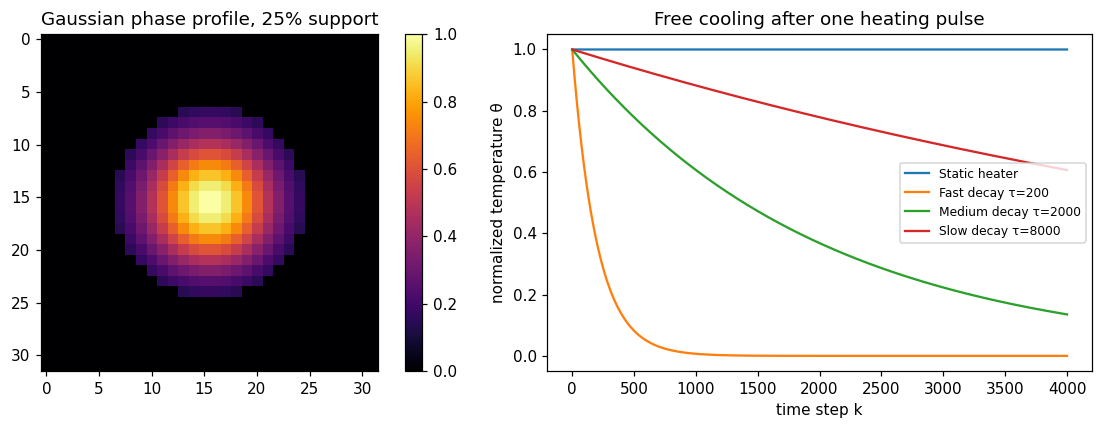

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
im = ax[0].imshow(optics.profile.cpu(), cmap='inferno', vmin=0, vmax=1)
ax[0].set_title('Gaussian phase profile, 25% support'); fig.colorbar(im, ax=ax[0])
times = np.arange(4001)
for condition in conditions[1:]:
    ax[1].plot(times, condition.temperature(times, DT), label=condition.name)
ax[1].set(xlabel='time step k', ylabel='normalized temperature θ', title='Free cooling after one heating pulse')
ax[1].legend(fontsize=8); fig.tight_layout(); plt.show()

## 3. 固定 probe：逐组观察 speckle

固定 $u_k=0.5$，在各时刻使用同一个入射光场；因此图像变化来自热相位屏。所有图共用色标，数值是 $|E|^2$，不对每一帧分别做 min–max 归一化。右侧图显示与**无热 speckle**的空间 Pearson 相关系数；它描述 speckle 变化，不直接代表信息记忆容量。

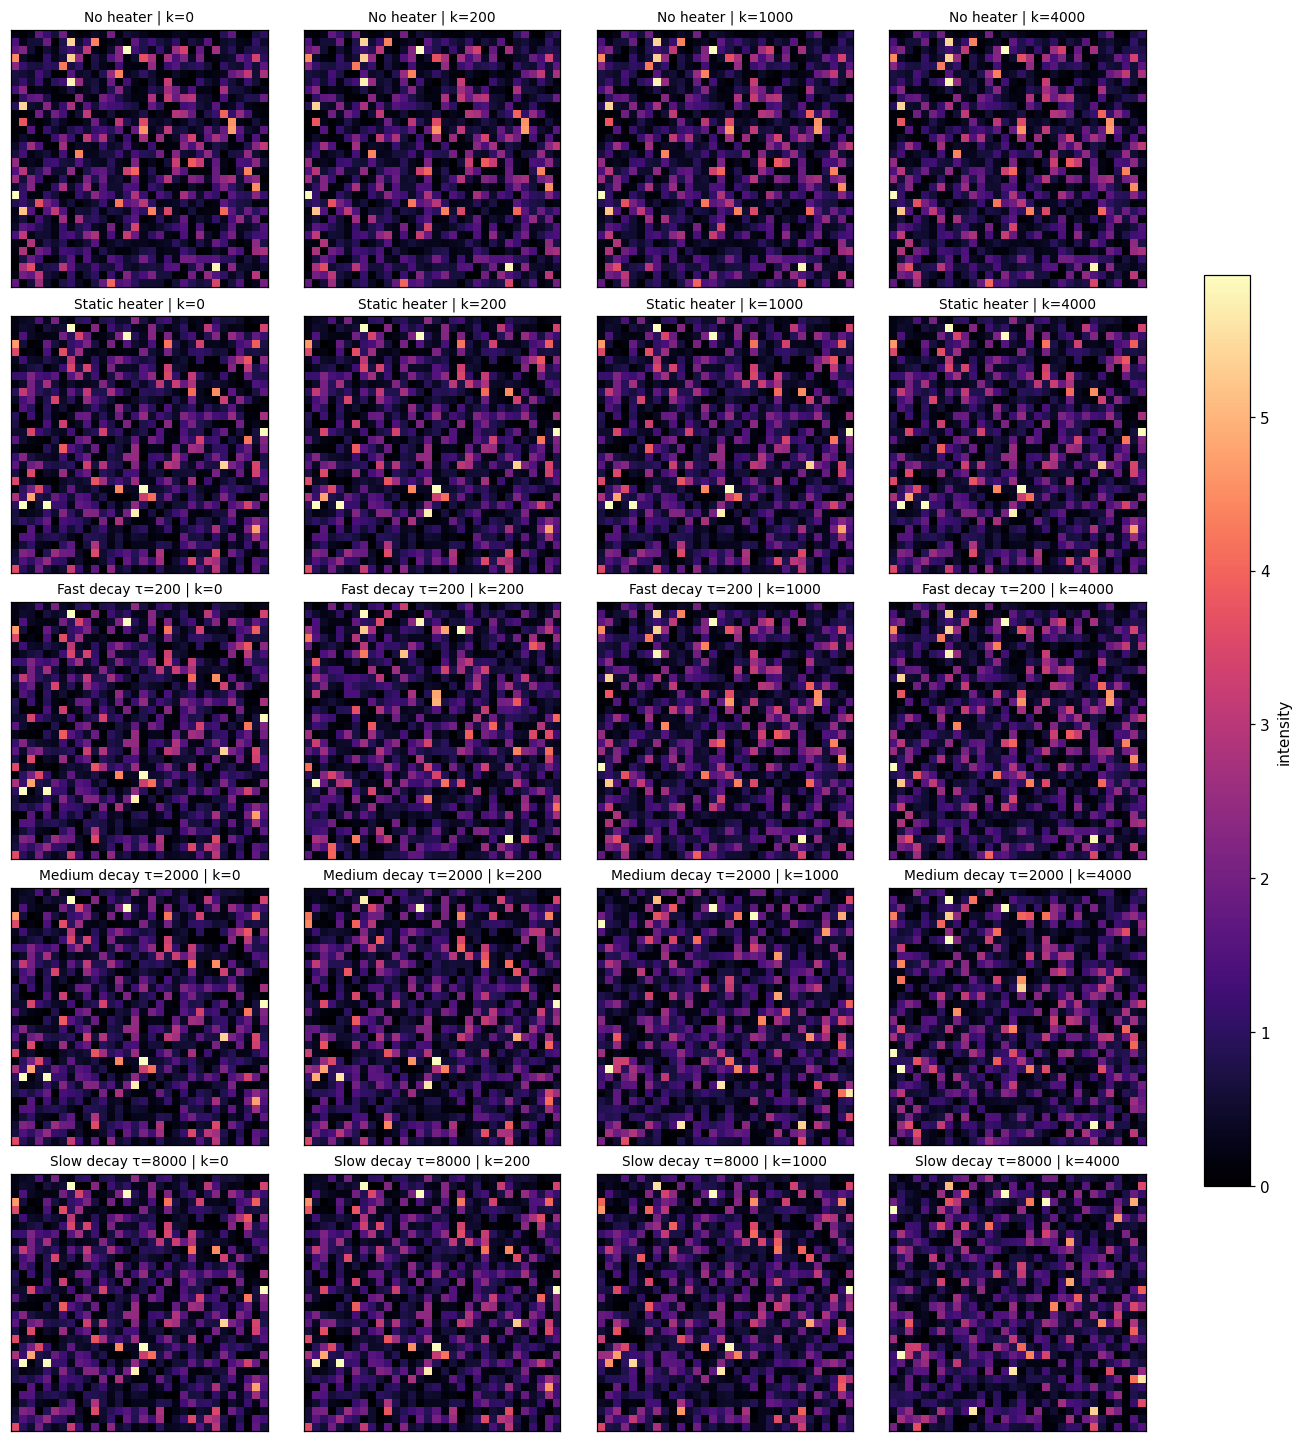

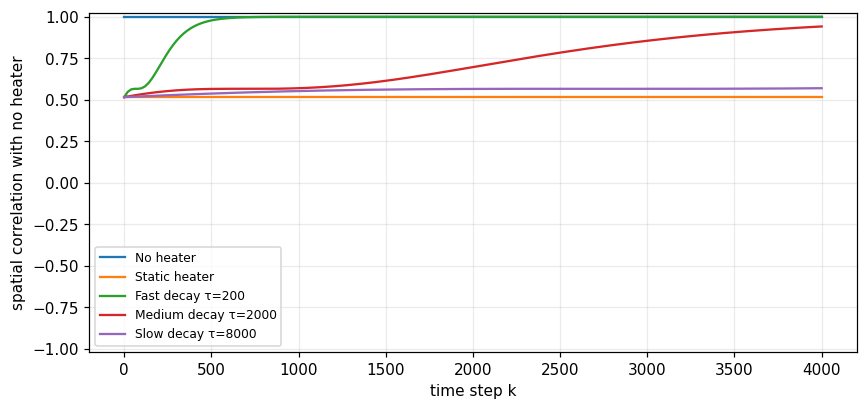

In [3]:
snap_times = np.array([0, 200, 1000, 4000])
probe = np.full(len(snap_times), 0.5)
reference = optics.intensity([0.5], [0.0], PHASE_MAX)[0]
all_frames = {c.name: optics.intensity(probe, c.temperature(snap_times, DT), c.phase_max) for c in conditions}
vmax = max(np.percentile(frames, 99.5) for frames in all_frames.values())
fig, axes = plt.subplots(len(conditions), len(snap_times), figsize=(12, 13), constrained_layout=True)
for row, condition in enumerate(conditions):
    for col, k in enumerate(snap_times):
        im = axes[row, col].imshow(all_frames[condition.name][col], cmap='magma', vmin=0, vmax=vmax)
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
        axes[row, col].set_title(f'{condition.name} | k={k}', fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.65, label='intensity'); plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for condition in conditions:
    theta = condition.temperature(times[::20], DT)
    frames = optics.intensity(np.full(len(theta), 0.5), theta, condition.phase_max)
    ax.plot(times[::20], spatial_correlation(frames, reference), label=condition.name)
ax.set(xlabel='time step k', ylabel='spatial correlation with no heater', ylim=(-1.02, 1.02))
ax.legend(fontsize=8); ax.grid(alpha=.25); plt.show()

## 4. 相同当前输入、不同历史

随机产生两条不同历史，在相同时刻给它们同一个当前输入。自由冷却的 $\theta_k$ 不依赖之前的输入，因此相同当前输入必然得到相同的输出。这是本模型没有输入历史记忆的直接检验。

In [4]:
rng = np.random.default_rng(10)
history_a = rng.random(41); history_b = rng.random(41)
history_a[-1] = history_b[-1] = 0.5
case = conditions[3]
theta = case.temperature(np.arange(len(history_a)), DT)
frame_a = optics.intensity(history_a, theta, case.phase_max)[-1]
frame_b = optics.intensity(history_b, theta, case.phase_max)[-1]
print('Different earlier inputs:', not np.array_equal(history_a[:-1], history_b[:-1]))
print('Max |speckle A - speckle B| at same time/current input:', np.max(np.abs(frame_a-frame_b)))
assert np.allclose(frame_a, frame_b, atol=1e-7)

Different earlier inputs: True
Max |speckle A - speckle B| at same time/current input: 0.0


## 5. Mackey–Glass：逐组 one-step prediction

本地 `MackeyGlass_t17.txt` 是用户已有序列。时间顺序划分：前 2000 点训练，后 2000 点测试；训练期间的缩放用于测试。训练目标为 $y_k=u_{k+1}$，测试时每步输入真实 $u_k$（teacher forcing），没有预测输出或 CCD 电子反馈。自由冷却从训练开始持续到测试结束，**不在 train/test 之间重新加热**。

每个读出接收当前 $u_k$ 和当前 speckle 特征，使用同样的 ridge 参数。另列 $\hat y_{k+1}=u_k$ 的 persistence 及只用当前输入的线性 readout。NRMSE 使用测试目标的标准差。为避免分界处目标泄漏，训练的最后一个目标仍在训练时间段内。

In [5]:
data_file = Path('MackeyGlass_t17.txt')
if not data_file.exists():
    raise FileNotFoundError('Put MackeyGlass_t17.txt next to this notebook, or set data_file to its path.')
series = np.loadtxt(data_file).reshape(-1)
n_train, n_test = 2000, 2000
assert len(series) >= n_train+n_test+1
train_min, train_max = series[:n_train].min(), series[:n_train].max()
u_raw = (series[:n_train+n_test]-train_min)/(train_max-train_min)
u = np.clip(u_raw, 0, 1)
y = (series[1:n_train+n_test+1]-train_min)/(train_max-train_min)
train_idx = np.arange(n_train-1)  # target remains inside training interval
test_idx = np.arange(n_train, n_train+n_test)
k = np.arange(len(u))
print('Clipped test input fraction:', np.mean(u_raw[test_idx] != u[test_idx]))
predictions = {'Persistence': u[test_idx],
               'Current input linear': ridge_predict(u[train_idx, None], y[train_idx], u[test_idx, None])}
for c in conditions:
    features = optics.features(u, c.temperature(k, DT), c.phase_max)
    z = np.column_stack((u, features))
    predictions[c.name] = ridge_predict(z[train_idx], y[train_idx], z[test_idx])
print(f"{'Condition':<26} {'RMSE':>10} {'NRMSE':>10}")
for name, pred in predictions.items():
    s = scores(y[test_idx], pred)
    print(f"{name:<26} {s['RMSE']:10.5f} {s['NRMSE']:10.5f}")

Clipped test input fraction: 0.0
Condition                        RMSE      NRMSE
Persistence                   0.03769    0.14607
Current input linear          0.03760    0.14573
No heater                     0.03827    0.14833
Static heater                 0.03846    0.14906
Fast decay τ=200              0.03815    0.14785
Medium decay τ=2000           0.04139    0.16043
Slow decay τ=8000             0.03933    0.15242


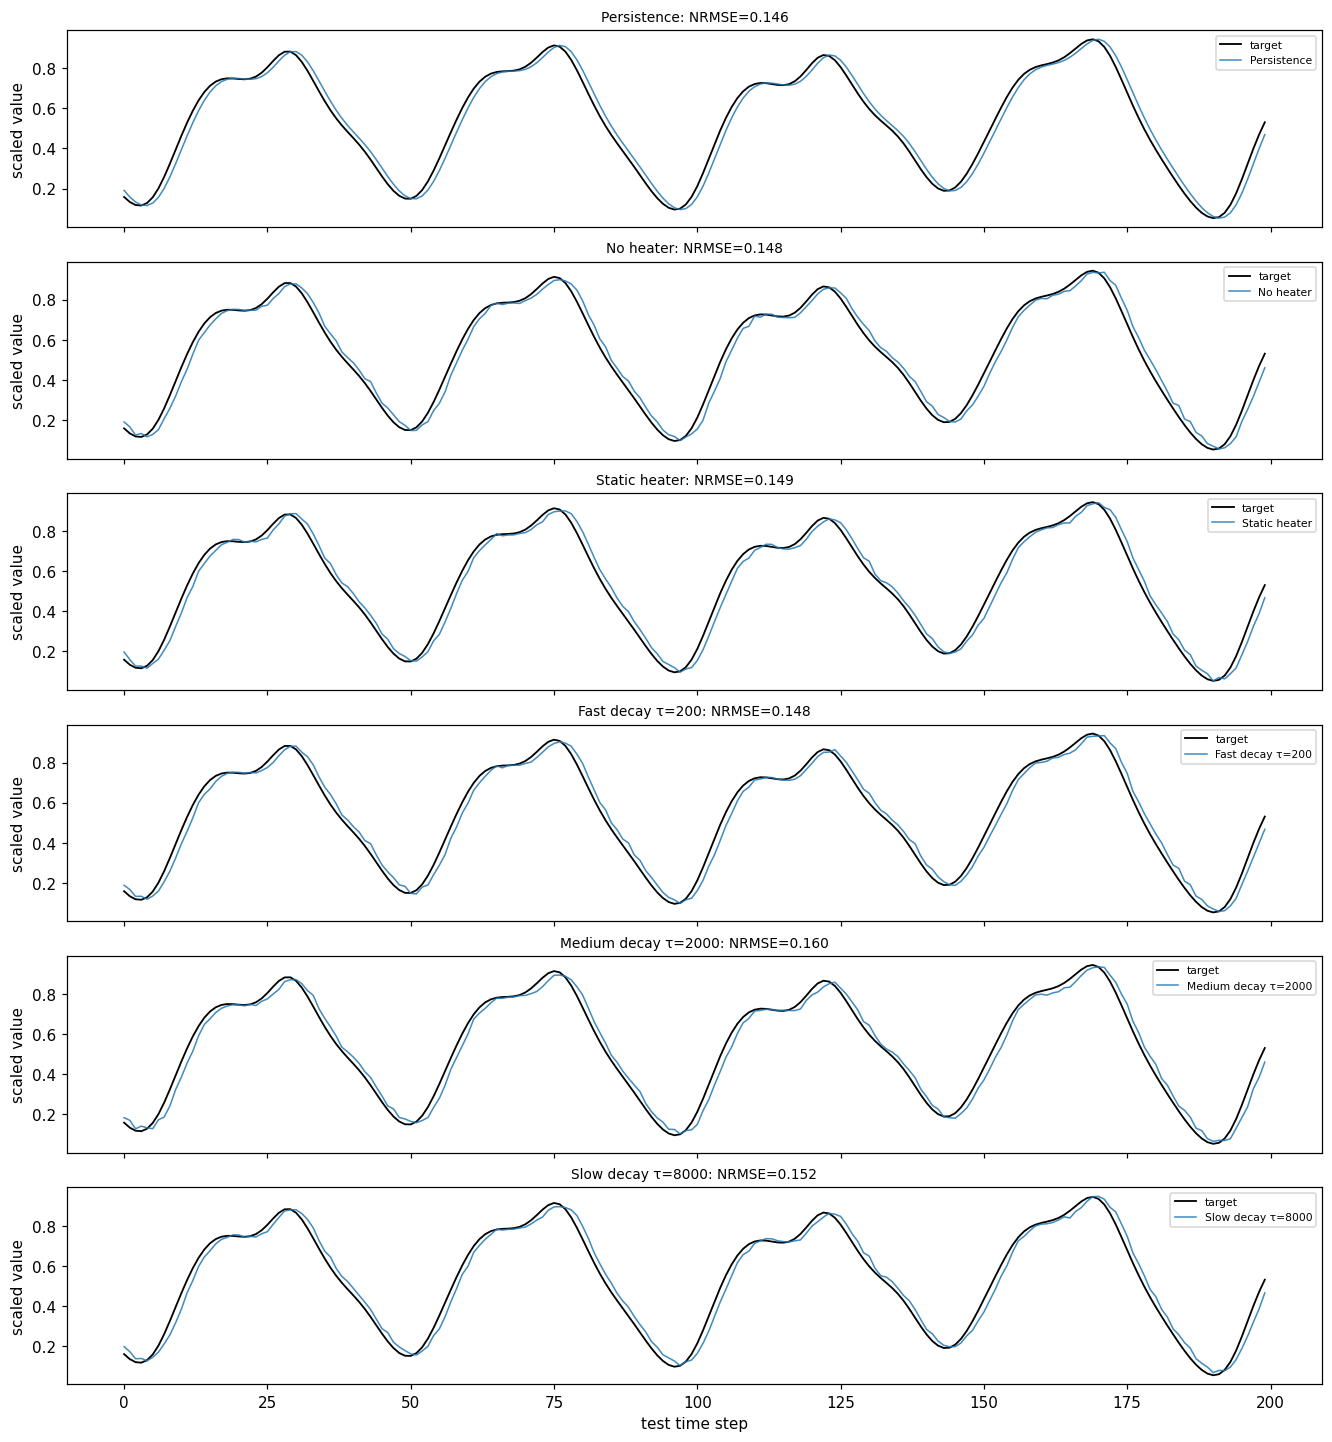

In [6]:
fig, axes = plt.subplots(len(conditions)+1, 1, figsize=(12, 13), sharex=True, constrained_layout=True)
view = slice(0, 200)
for ax, name in zip(axes, ['Persistence'] + [c.name for c in conditions]):
    ax.plot(y[test_idx][view], 'k', lw=1.2, label='target')
    ax.plot(predictions[name][view], lw=1, alpha=.85, label=name)
    ax.set_ylabel('scaled value'); ax.set_title(f"{name}: NRMSE={scores(y[test_idx], predictions[name])['NRMSE']:.3f}", fontsize=9)
    ax.legend(loc='upper right', fontsize=7)
axes[-1].set_xlabel('test time step'); plt.show()

## 6. 如何解释结果

1. 这些曲线显示，在相同随机介质下，自由冷却如何改变透射映射及 speckle。静态扰动给出固定瞬时映射；不同 $\tau$ 给出不同时间变化。
2. 因为没有输入写入热状态，输入历史检验中两条不同历史的输出相同。单次冷却可以保留**加热事件本身**的衰减痕迹，却不能储存之后的输入序列。
3. Mackey–Glass 相邻样本强相关；当前输入的静态映射也可能预测下一步。要把能力归因于热 fading memory，需要今后增加明确的输入依赖热写入，并与无写入条件对比；不需要电子反馈，但需要输入影响热状态。单一 $\theta$ 仅有一个独立热状态，不会因相机像素很多而自动产生很多独立记忆状态。
4. 此示例只比较一个随机种子、一个瞬态和固定 ridge；参数扫描、多个种子、物理噪声与实验标定是后续工作。

注：上一版 `thermal_disorder_rc.py` 使用了输入驱动 $\theta_{k+1}=a\theta_k+(1-a)u_k$；它不是这里的自由冷却模型，上一版报告的 memory-capacity 数值也不能用于当前无写入实验。